In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "diabetes.csv"  # Change this if your CSV is stored in another folder


In [6]:
df = pd.read_csv('/content/diabetes.csv')

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
display(df.head())


Dataset loaded successfully.
Number of rows: 768
Number of columns: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\\nStatistical summary:")
display(df.describe().T)


Shape: (768, 9)
\nColumn names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
\nData types:


,Data Type
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


\nMissing values:


,Missing Values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


\nStatistical summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Target class counts:


,count
Outcome,
No Diabetes,500
Diabetes,268


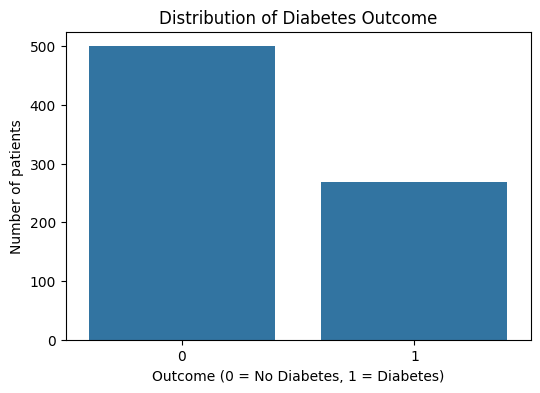

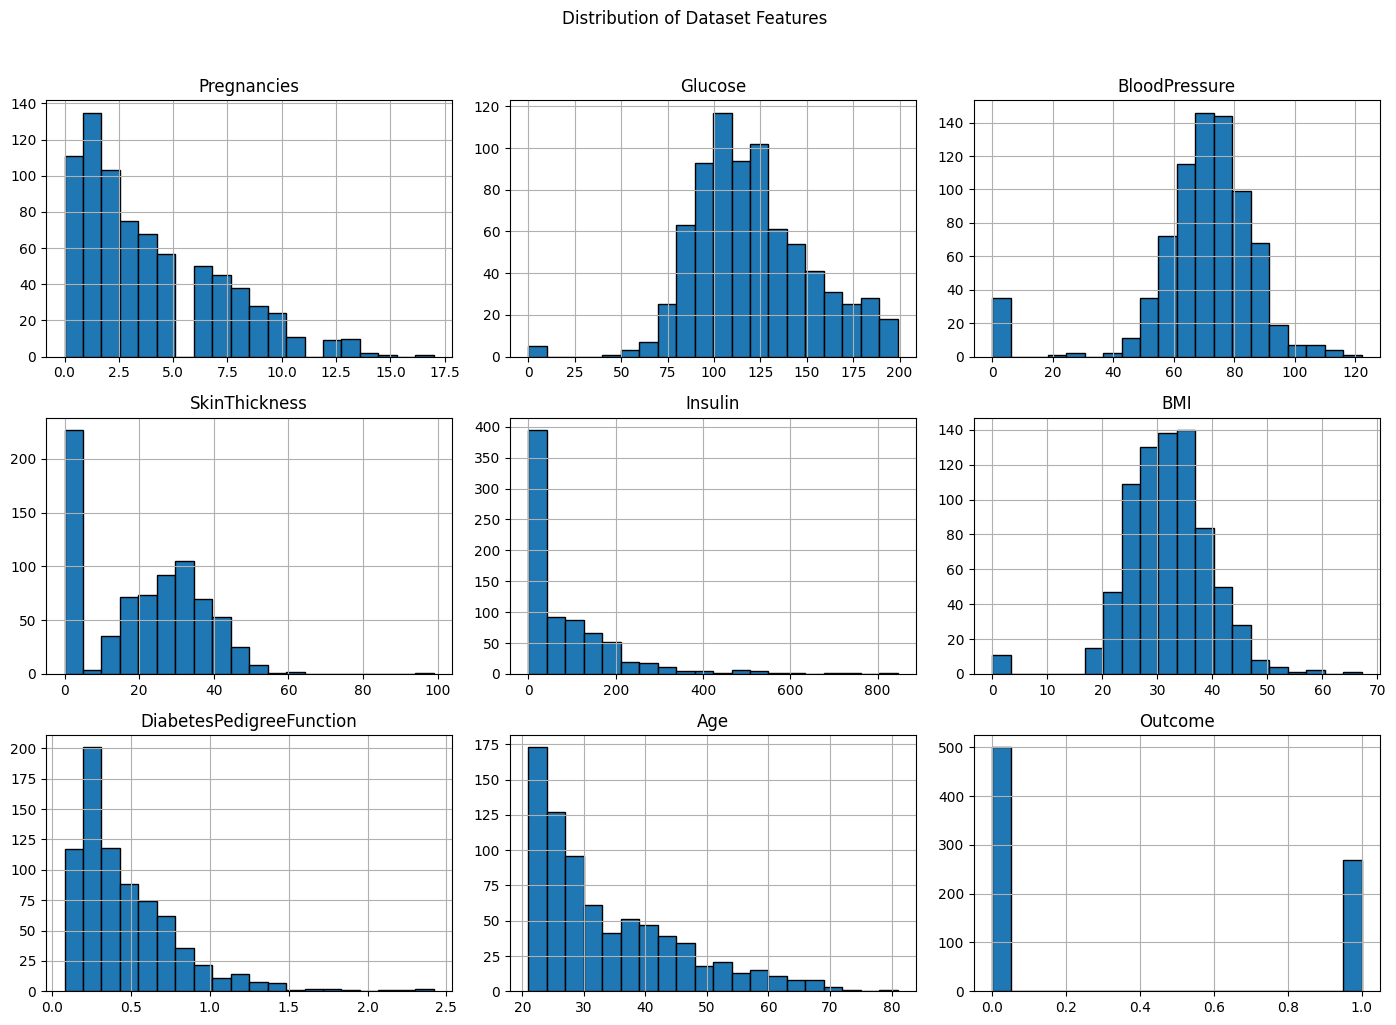

In [8]:
if "Outcome" not in df.columns:
    raise ValueError("The dataset must contain an 'Outcome' target column.")

print("Target class counts:")
display(df["Outcome"].value_counts().sort_index().rename(index={0: "No Diabetes", 1: "Diabetes"}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of patients")
plt.show()

df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Dataset Features", y=1.02)
plt.tight_layout()
plt.show()


In [9]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Features:", X.columns.tolist())
print("Target: Outcome")


Feature matrix shape: (768, 8)
Target vector shape: (768,)
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target: Outcome


In [10]:
# Treat zero measurements in these clinical columns as missing values.
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X_prepared = X.copy()
X_prepared[zero_as_missing] = X_prepared[zero_as_missing].replace(0, np.nan)

print("Missing values after replacing implausible zeros:")
display(X_prepared.isnull().sum().to_frame(name="Missing Values"))

X_train, X_test, y_train, y_test = train_test_split(
    X_prepared,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training features: {X_train.shape}")
print(f"Testing features:  {X_test.shape}")
print(f"Training target:   {y_train.shape}")
print(f"Testing target:    {y_test.shape}")


Missing values after replacing implausible zeros:


,Missing Values
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0


Training features: (614, 8)
Testing features:  (154, 8)
Training target:   (614,)
Testing target:    (154,)


In [11]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

print(model)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [12]:
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Model training completed.")
print("Sample training predictions:", y_train_pred[:10])
print("Sample testing predictions: ", y_test_pred[:10])


Model training completed.
Sample training predictions: [0 0 0 0 0 1 0 1 0 0]
Sample testing predictions:  [1 0 0 0 0 0 0 1 0 1]


In [13]:
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f} ({train_accuracy * 100:.2f}%)")
print(f"Testing Accuracy:  {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

print("\\nTesting Classification Report:")
print(classification_report(
    y_test, y_test_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Training": [
        train_accuracy,
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred, zero_division=0),
        f1_score(y_train, y_train_pred, zero_division=0)
    ],
    "Testing": [
        test_accuracy,
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
})
display(metrics_table.round(4))


Training Accuracy: 0.7964 (79.64%)
Testing Accuracy:  0.7078 (70.78%)
\nTesting Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



,Metric,Training,Testing
0,Accuracy,0.7964,0.7078
1,Precision,0.7697,0.6000
2,Recall,0.5935,0.5000
3,F1-Score,0.6702,0.5455


### 10. Confusion Matrix

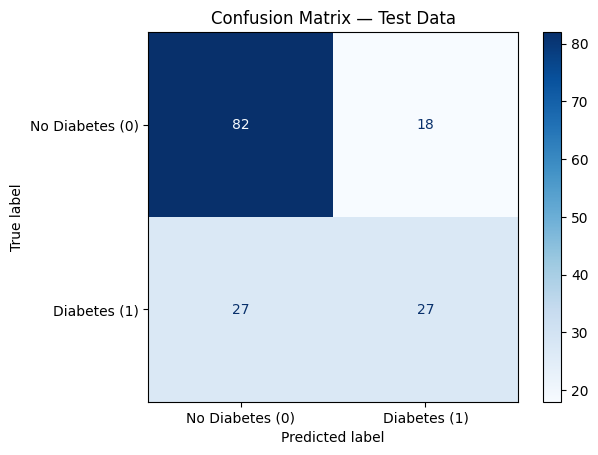

Confusion matrix:
[[82 18]
 [27 27]]


In [14]:
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Data")
plt.show()

print("Confusion matrix:")
print(cm)


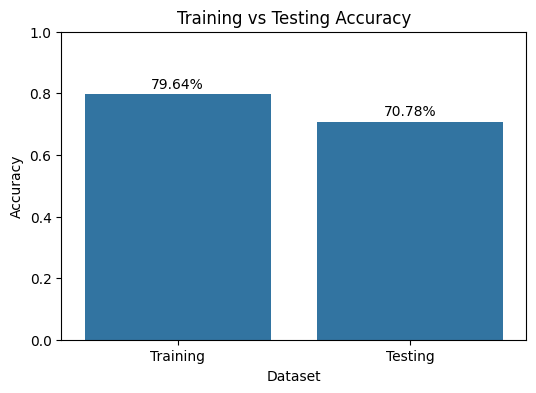

Training accuracy: 79.64%
Testing accuracy:  70.78%
Train-test accuracy difference: 8.86%


In [15]:
accuracy_comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [train_accuracy, test_accuracy]
})

plt.figure(figsize=(6, 4))
sns.barplot(data=accuracy_comparison, x="Dataset", y="Accuracy")
plt.ylim(0, 1)
plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy")
for index, value in enumerate(accuracy_comparison["Accuracy"]):
    plt.text(index, value + 0.02, f"{value:.2%}", ha="center")
plt.show()

accuracy_difference = train_accuracy - test_accuracy
print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Testing accuracy:  {test_accuracy:.2%}")
print(f"Train-test accuracy difference: {accuracy_difference:.2%}")


In [16]:
# Example input: Pregnancies, Glucose, BloodPressure, SkinThickness,
# Insulin, BMI, DiabetesPedigreeFunction, Age
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 30
}])

prediction = model.predict(new_patient)[0]
probability = model.predict_proba(new_patient)[0, 1]

print("Predicted class:", "Diabetes (1)" if prediction == 1 else "No Diabetes (0)")
print(f"Estimated probability for class 1: {probability:.2%}")
print("Educational demonstration only — not a medical diagnosis.")


Predicted class: No Diabetes (0)
Estimated probability for class 1: 17.84%
Educational demonstration only — not a medical diagnosis.
